# Real RF to a complete two-component mechanical velocity field


<!-- inverse-evidence-audit:20261026:start -->

> **本次维护说明：** 以下导航依据当前观测文件、实际求解代码和保留的输出编写。本次仅完善叙述，不把历史图、缓存结果或未执行代码称作本次新计算；没有独立 GT 时，方法参考不代表真实准确性。

### 观测 → 物理目标：rotating_disk_ultrasound_vector_field

**观测 y：** rf(1, 32, 128, 334)；observation_roi(1, 251, 251)；x(1, 251)；z(1, 251)。具体单位以本Notebook数据表及README为准。

**恢复目标 x：** 旋转盘完整二维速度矢量。

**GT/参考来源：** **没有独立GT：以下仅为原方法参考重建，不能解释为物理真值。**

**由观测恢复目标：** RF传播和双接收角相位由速度的双基地投影产生。本地路径为 `solvers.reconstruct→beamform→doppler_velocity→robust_smooth`。现有Notebook包含主动调用路径；本次只读审核未重跑，保留的execution_count/图像只说明已有输出，不能声称本轮执行。

**现有实验与图：** 保留图像输出位于cell 3, 8, 10, 12, 14（cell编号按文件内从0计）。章节包括：# Real RF to a complete two-component mechanical velocity field；## 2. Observations: the entire existing measured acquisition；Figure1 shows the actual measured counts, all-trace spectrum and known geometry. The plotted sampled peak is an alias of the physical5MHz carrier; the physical carrier is retained in travel-time focusing and velocity conversion. Spectral zero-padding only interpolates the display. The disk boundary is input geometry, never inferred from a force/velocity reference.；## 4. Method: explicit RF inverse and robust spatial updates；## 5. Results: complete fields, source parity and measured phase；Figure3 compares all31,404 pixels of each component against the separate official-author run; exterior is standardized to the declared zero convention for both. These are numerical reproduction differences, not true-speed errors. The signed maps have symmetric zero-centred limits. Exact zero histogram differences use a disclosed$10^{-18}$ display floor; the full numeric arrays retain exact zeros. Frozen nonzero reproduction limits were measured from independent original arithmetic/serialization runs before any local reconstruction.；The phasor check compares both predicted signed phases with correlations independently derived from the public RF. Its weighted complex-chord RMS is distinct from the wrapped-angle histograms in Figure4. Weight is echo correlation magnitude, not a calibrated noise likelihood. The raw algebraic inverse can fit the two Doppler phases almost exactly and still exhibit noisy lateral outliers; phase fit alone is insufficient. The selected spatial prior has a small measured phase residual, while zero/sign-reversed fields fail strongly.；Figure5 preserves raw-versus-regularized comparison and actively evaluates additional quadratic/robust scales on the same RF. Each bar is measured, including the genuinely zero raw-from-raw vector discrepancy. Some alternatives do not meet the **selected estimate's** evaluation boundary; no threshold is retuned to admit them. Weights plotted are those used in the final solve, determined by the previous robust pass; the returned weights recomputed after the final pass are separately recorded and do not trigger an invented fourth solve. Downweighting is not a truth label for a pixel.；## 6. Conclusion: what is and is not established。应联合阅读观测图、完整恢复目标、参考差异与残差/敏感性实验；方法一致性不等于物理精度。

**限制：** 未知转速不得当真值；相位检查不等于真实速度GT。

<!-- inverse-evidence-audit:20261026:end -->


## 1. Problem: infer motion, not a scalar rotation calibration

We recover lateral and depth velocity at every pixel of a real rotating disk from all128 receive channels and32 ultrasound pulses. RF carrier undersampling, phase periodicity, noisy lateral sensitivity and a spatial prior all matter. The full known disk support is31,404 pixels; the output has both components on the251 by251 grid with a documented zero exterior.

The independently executed official-author MATLAB recipe supplies a **method reference**, not measured true velocity. This notebook actively runs the local explicit mathematics. Original, fresh and additional diagnostics are kept distinct. Neither a fitted rigid rotation nor an archived result replaces the field inverse.

In [1]:
from pathlib import Path
import os,sys,time,json,hashlib,platform,importlib.util
import numpy as np
import scipy
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display,Markdown
sys.dont_write_bytecode=True
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'data/raw_data.npz').is_file())
sys.path.insert(0,str(ROOT))
from src.preprocessing import load_observations
from src.solvers import reconstruct,robust_smooth
from src.physics_model import doppler_velocity,invert_receive_projections,phase_consistency,predicted_radial
from src import visualization as viz
viz.style()
FIGURES=os.environ.get('IMAGING_FIGURE_DIR')
environment={'sys_executable':sys.executable,'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'matplotlib':matplotlib.__version__,'backend':matplotlib.get_backend(),'threads':{k:os.environ.get(k) for k in ['OMP_NUM_THREADS','OPENBLAS_NUM_THREADS','MKL_NUM_THREADS','NUMEXPR_NUM_THREADS']}}
print(json.dumps(environment,indent=2))

{
  "sys_executable": "D:\\yan1\\agent\\AutoSkill\\imaging-101-maintainer\\research-runtime\\Scripts\\python.exe",
  "python": "3.11.11",
  "numpy": "2.4.6",
  "scipy": "1.17.1",
  "matplotlib": "3.11.1",
  "backend": "module://matplotlib_inline.backend_inline",
  "threads": {
    "OMP_NUM_THREADS": "1",
    "OPENBLAS_NUM_THREADS": "1",
    "MKL_NUM_THREADS": "1",
    "NUMEXPR_NUM_THREADS": "1"
  }
}


## 2. Observations: the entire existing measured acquisition

The public file contains ADC counts, coordinate axes and the author's known geometric support, without estimated velocities. Native RF order is334 fast-time samples by128 elements by32 pulses. The array transmits a normal plane wave; both receive views use the same RF. Sound speed is1480m/s, carrier5MHz, saved RF rate6.6667MHz and pulse repetition10kHz. First fast-time sample is9.95microseconds. The saved rate is already retrospectively reduced; no original high-rate waveform is recoverable by relabeling these data.

The example is a2cm disk with32 pulses, whereas the2018 historical experiment uses a different disk/acquisition. Published high-rate numerical comparisons are context, not measurements reproduced on this file. Software is the exact independently archived official author ZIP; the separately identified Python port failed before local extraction.

{'rf': ((334, 128, 32), 'float64'), 'roi': ((251, 251), 'bool'), 'x': ((251,), 'float64'), 'z': ((251,), 'float64')}
Known support pixels: 31404 RF minimum/maximum: -2667.0 2667.0


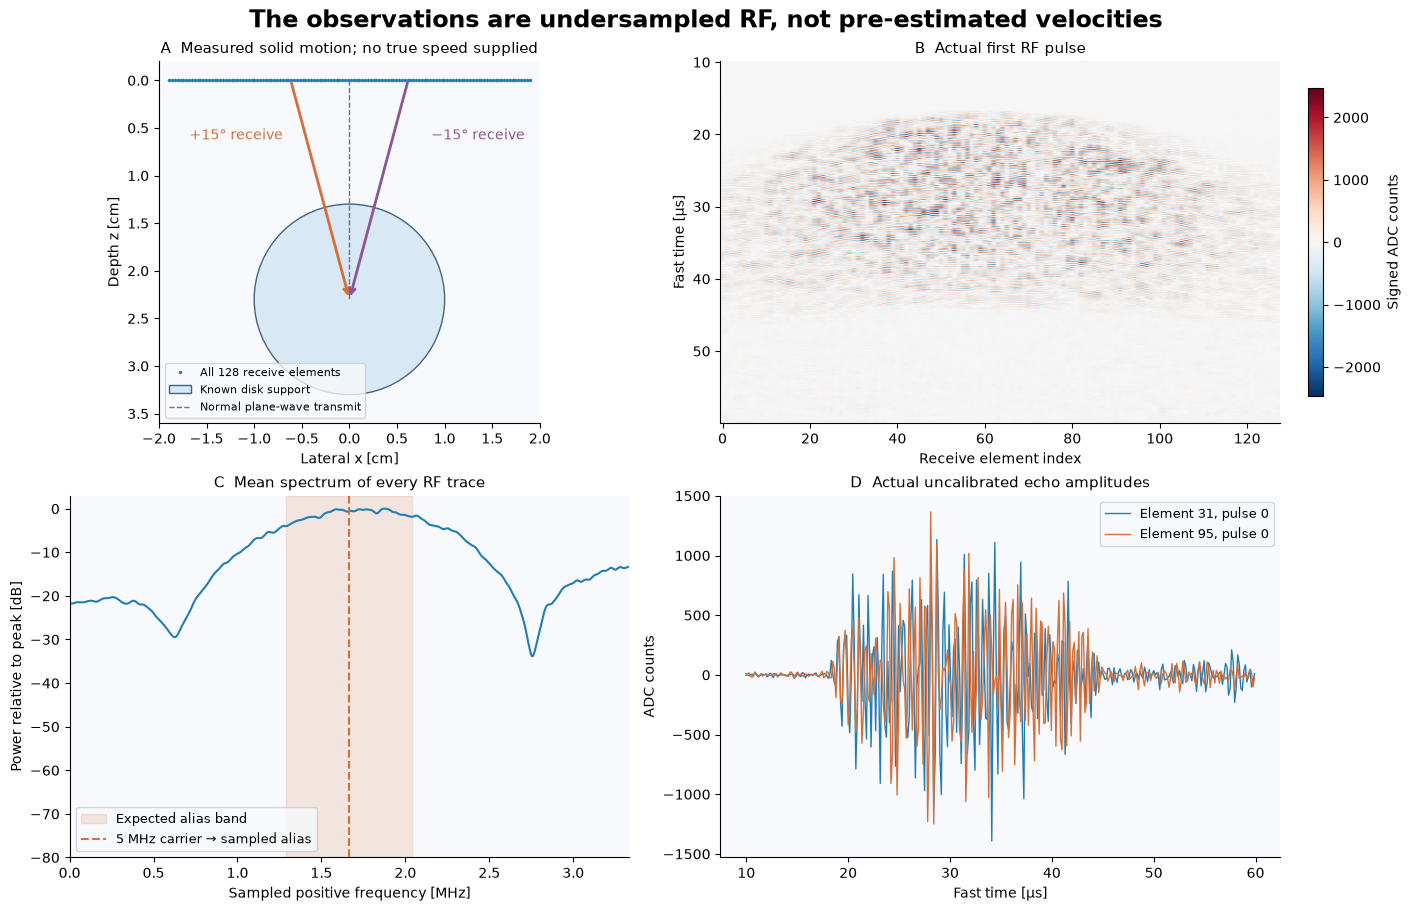

In [2]:
observations=load_observations(ROOT/'data/raw_data.npz')
raw_hash=hashlib.sha256((ROOT/'data/raw_data.npz').read_bytes()).hexdigest()
print({k:(v.shape,str(v.dtype)) for k,v in observations.items()})
print('Known support pixels:',int(observations['roi'].sum()),'RF minimum/maximum:',float(observations['rf'].min()),float(observations['rf'].max()))
fig,numeric=viz.plot_observations(observations)
viz.export_figure(fig,'figure01_measured_rf',FIGURES,numeric);plt.show()

Figure1 shows the actual measured counts, all-trace spectrum and known geometry. The plotted sampled peak is an alias of the physical5MHz carrier; the physical carrier is retained in travel-time focusing and velocity conversion. Spectral zero-padding only interpolates the display. The disk boundary is input geometry, never inferred from a force/velocity reference.

## 3. Physics: two receive directions constrain two components

For signed focused Doppler estimates $d_+$ and $d_-$ from receive angles plus/minus $\theta=15^\circ$, normal transmission gives

$$d_\pm=-\frac12[\pm\sin\theta\,v_x+(1+\cos\theta)v_z],\qquad
v_x=\frac{d_--d_+}{\sin\theta},\quad
v_z=-\frac{d_-+d_+}{1+\cos\theta}.$$

Here $v_x$ increases laterally, $v_z$ increases away from the transducer, and all velocities are in m/s. The small angular difference amplifies lateral errors. Each complex pulse packet $I_q$, with pulse index $q$, gives lag-$l$ correlation and signed velocity

$$A_l=\sum_{q=0}^{31-l}I_q\overline{I_{q+l}},\qquad
d=-\frac{V_N}{\pi}\arg A_l,\qquad V_N=\frac{c f_p}{4f_c l}.$$

The overline is complex conjugation, $c$ sound speed, $f_p$ pulse repetition and $f_c$ physical carrier. Lag1 uses all31 pairs and $V_N=.74$m/s. Correlation and packet power are averaged with the same11 by11 Hamming window and replicated edges. The finite-packet variance estimator is retained, rather than advertised as a calibrated uncertainty probability.

Coherent focusing locally evaluates the selected author's parabolic virtual-array transmit distance, geometric receive distance, known element-directivity aperture, linear fast-time interpolation and complex carrier rotation. These operators are explicit in `src`; no ultrasound-domain package is invoked.

## 4. Method: explicit RF inverse and robust spatial updates

We demodulate every RF trace with the physical carrier and the selected fifth-order forward/reverse low-pass. Both receive operators focus all32 pulses over the complete grid, and the two-angle formula recovers both raw components. The selected author recipe then uses fixed smoothing scale $s=10^4$ and three vector-bisquare passes.

For a component $y$, fixed pixel weights $W$ and repeating-boundary grid Laplacian $L$, the conditional penalty is

$$J(u)=\tfrac12\|W^{1/2}(u-y)\|_F^2+\tfrac{s}{2}\|Lu\|_F^2.$$

The estimate $u$ is updated by a relaxed weighted DCT inverse. DCT-II eigenvalues are $\Lambda_{kl}=4-2\cos(\pi k/H)-2\cos(\pi l/W_g)$, where $H=W_g=251$ are row/column counts, and $k,l$ are zero-based frequency indices. To distinguish grid width $W_g$ from pointwise weights $W$, the two use different symbols. The scalar spectral multiplier is $1/(1+s\Lambda^2)$, relaxation1.75, and exterior weights0. The initial mean-filled field retains the lowest26 DCT coefficients per axis.

Each inner pass stops at relative joint field change below$10^{-3}$ or100 updates. Original and local first passes reach that100-update budget; the original final convergence flag refers only to the last robust pass. This finite protocol defines the selected conditional numerical reference. It is not a claim of a globally converged robust optimum or high-precision true mechanical speed.

In [3]:
started=time.perf_counter()
result=reconstruct(observations)
reconstruction_seconds=time.perf_counter()-started
(ROOT/'output').mkdir(exist_ok=True)
np.savez_compressed(ROOT/'output/reconstruction.npz',reconstruction=result['velocity'][None])
spec=importlib.util.spec_from_file_location('independent_notebook_judge',ROOT/'evaluation/judge.py')
judge=importlib.util.module_from_spec(spec);spec.loader.exec_module(judge)
report,exitcode=judge.evaluate(ROOT/'output/reconstruction.npz')
assert exitcode==0,report
(ROOT/'output/judge_report.json').write_text(json.dumps(report,indent=2),encoding='utf8')
config=json.loads((ROOT/'evaluation/metrics.json').read_text())
thresholds={k:{'nrmse_boundary':config['thresholds'][k+'_nrmse']['boundary']} for k in ['vx','vz']}
print('Fresh complete RF inverse seconds:',reconstruction_seconds)
print('Actual bounded inner passes:',json.dumps(result['smoothing']['history'],indent=2))
print('Independent all-component and RF-phase evaluation:',json.dumps(report,indent=2))

Fresh complete RF inverse seconds: 3.2178455000102986
Actual bounded inner passes: [
  {
    "robust_step": 1,
    "iterations": 100,
    "relative_change": 0.0022206293909106094,
    "converged": false
  },
  {
    "robust_step": 2,
    "iterations": 43,
    "relative_change": 0.0009977235547358643,
    "converged": true
  },
  {
    "robust_step": 3,
    "iterations": 12,
    "relative_change": 0.0009915145713361665,
    "converged": true
  }
]
Independent all-component and RF-phase evaluation: {
  "status": "pass",
  "passed": true,
  "metrics": {
    "vx_ncc": 1.0,
    "vx_nrmse": 4.9102137563055166e-15,
    "vz_ncc": 1.0,
    "vz_nrmse": 1.034358962900707e-15,
    "weighted_phasor_rms": 0.05201278063077122,
    "outside_support_maxabs": 0.0
  },
  "thresholds": {
    "vx_ncc": {
      "comparison": ">=",
      "boundary": 0.9999999999999956
    },
    "vx_nrmse": {
      "comparison": "<=",
      "boundary": 3.1279966911092165e-08
    },
    "vz_ncc": {
      "comparison": ">=",
 

## 5. Results: complete fields, source parity and measured phase

Every standard-result image below is computed from the fresh RF inverse above. White exterior denotes the known excluded disk exterior, not missing submitted values. All declared output exterior entries are zero. Common signed limits in Figure2 are explicitly clipped only for display; colorbar extensions and counts identify raw outliers. No result is numerically clipped or repaired.

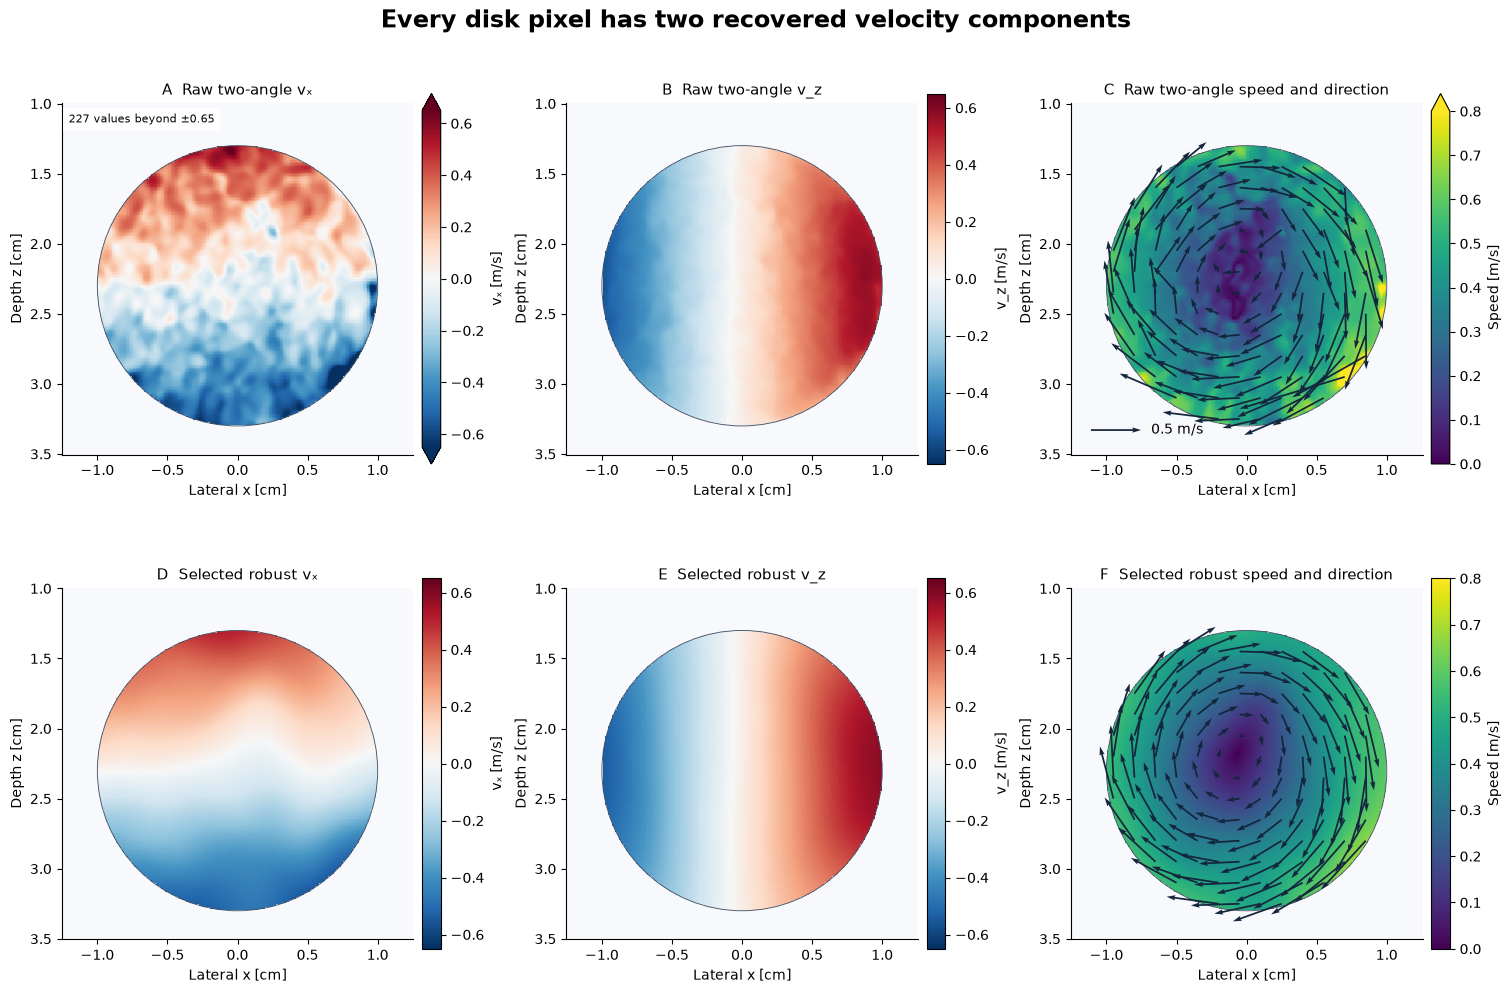

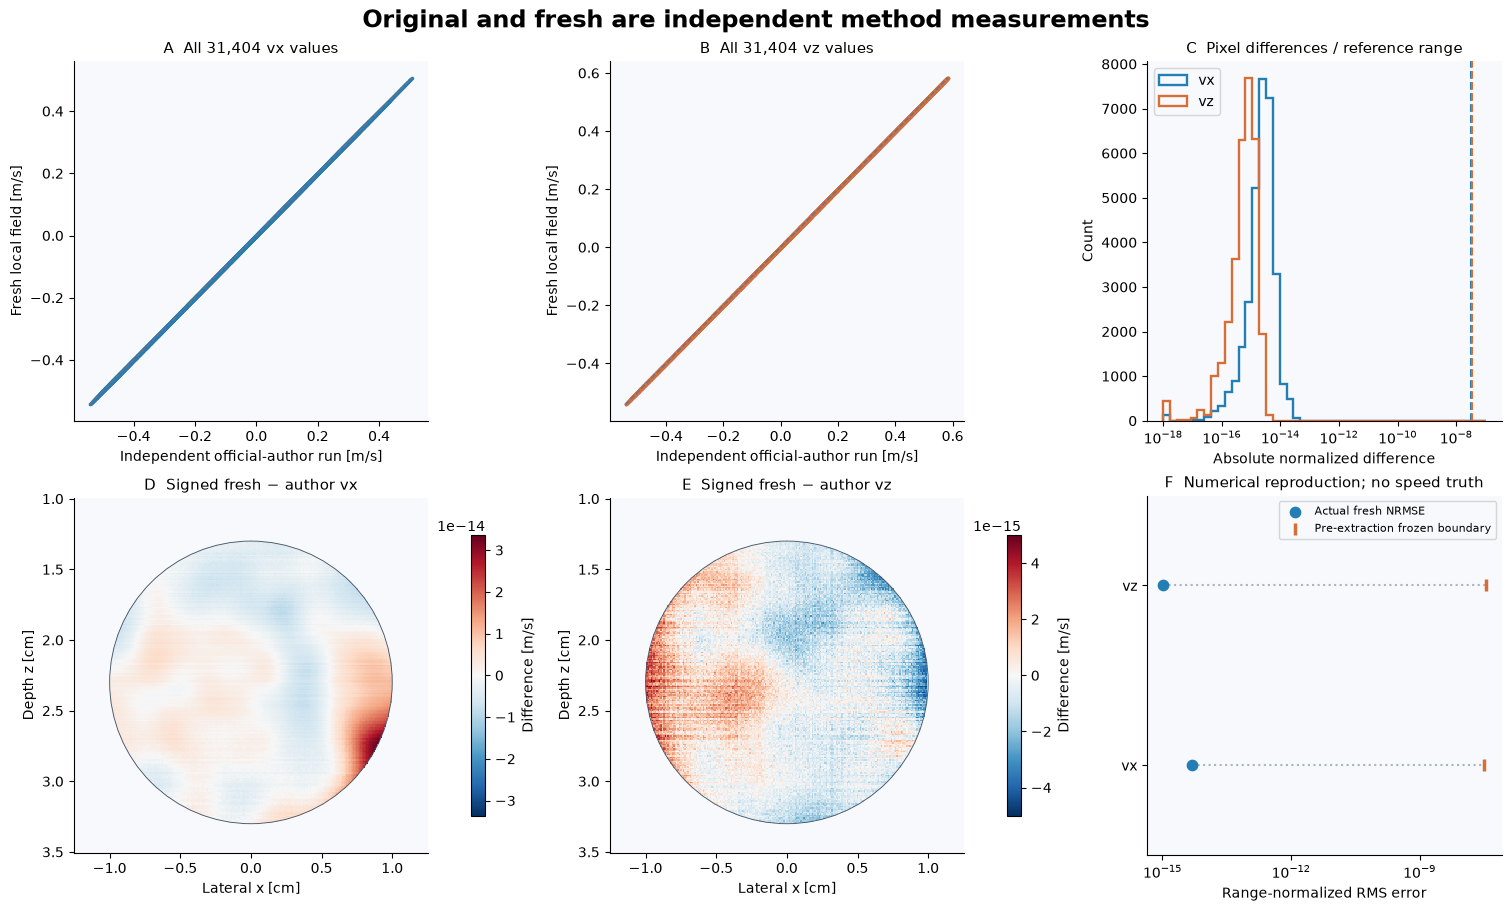

In [4]:
fig,numeric=viz.plot_atlas(result)
viz.export_figure(fig,'figure02_full_vector_atlas',FIGURES,numeric);plt.show()
with np.load(ROOT/'notebooks/reference_outputs/original_results.npz',allow_pickle=False) as d:
    original={k:d[k] for k in d.files}
fig,numeric=viz.plot_parity(result,original,thresholds)
viz.export_figure(fig,'figure03_original_local_parity',FIGURES,numeric);plt.show()

Figure3 compares all31,404 pixels of each component against the separate official-author run; exterior is standardized to the declared zero convention for both. These are numerical reproduction differences, not true-speed errors. The signed maps have symmetric zero-centred limits. Exact zero histogram differences use a disclosed$10^{-18}$ display floor; the full numeric arrays retain exact zeros. Frozen nonzero reproduction limits were measured from independent original arithmetic/serialization runs before any local reconstruction.

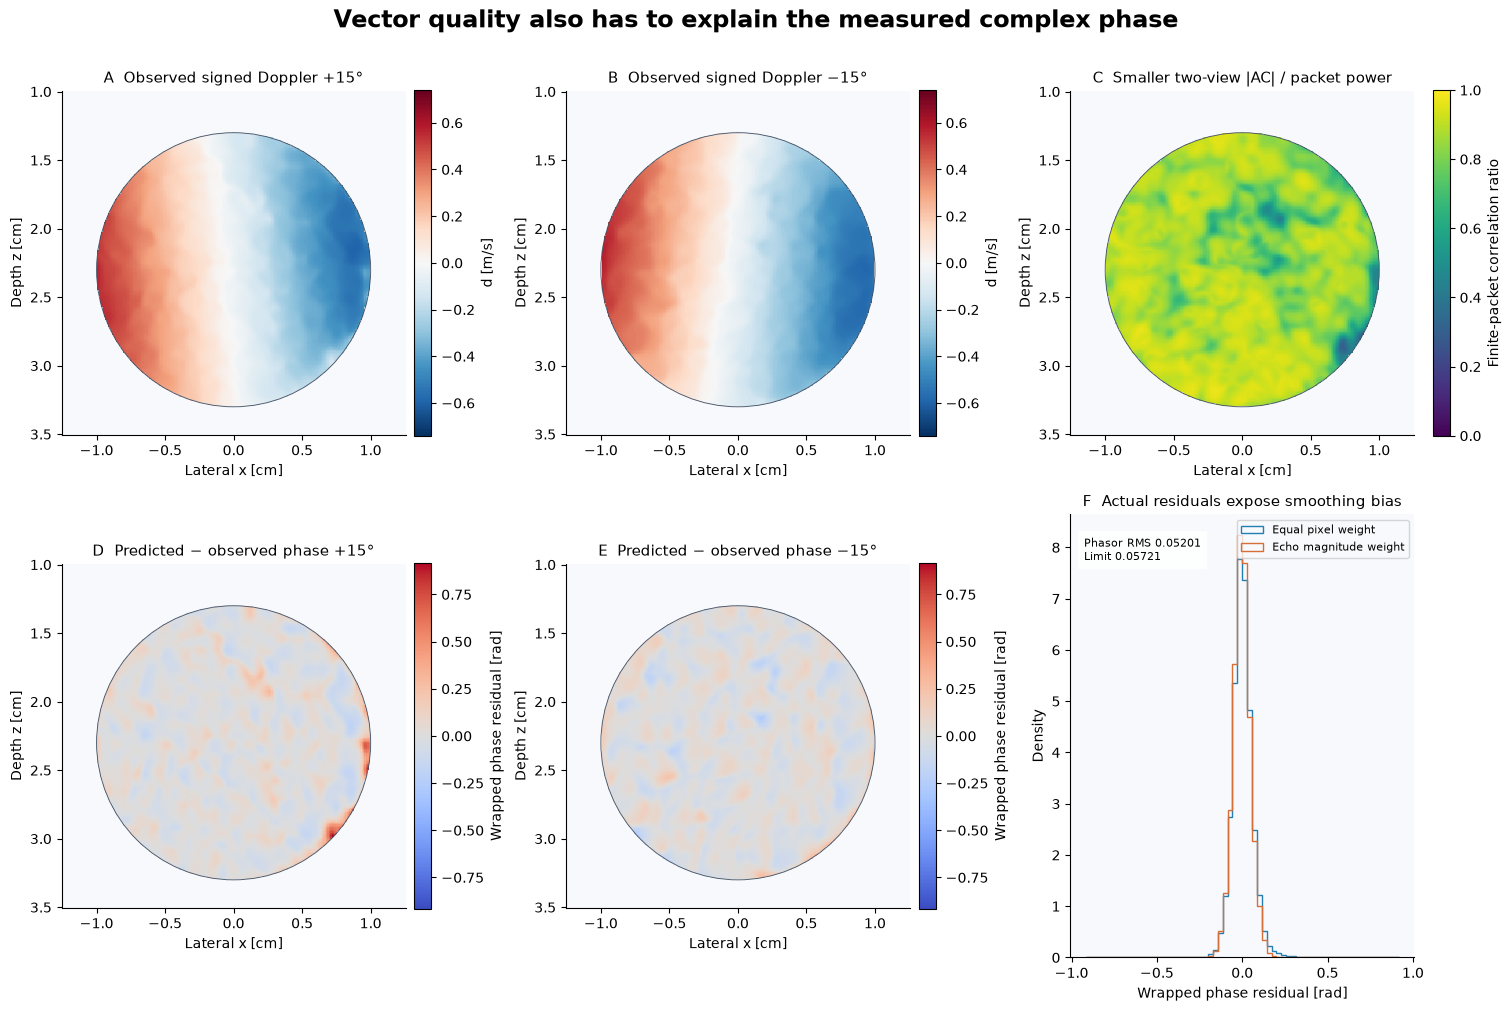

In [5]:
phase_limit=config['thresholds']['weighted_phasor_rms']['boundary']
fig,numeric=viz.plot_phase(result,phase_limit)
viz.export_figure(fig,'figure04_phase_consistency',FIGURES,numeric);plt.show()

The phasor check compares both predicted signed phases with correlations independently derived from the public RF. Its weighted complex-chord RMS is distinct from the wrapped-angle histograms in Figure4. Weight is echo correlation magnitude, not a calibrated noise likelihood. The raw algebraic inverse can fit the two Doppler phases almost exactly and still exhibit noisy lateral outliers; phase fit alone is insufficient. The selected spatial prior has a small measured phase residual, while zero/sign-reversed fields fail strongly.

Additional fields now reuse **fresh complex beams**, keeping RF demodulation/focusing fixed while actually changing each requested phase/smoothing condition. This saves identical work without reading a cached reconstruction. These comparisons expose prior and acquisition sensitivity, not a new independent mechanical truth.

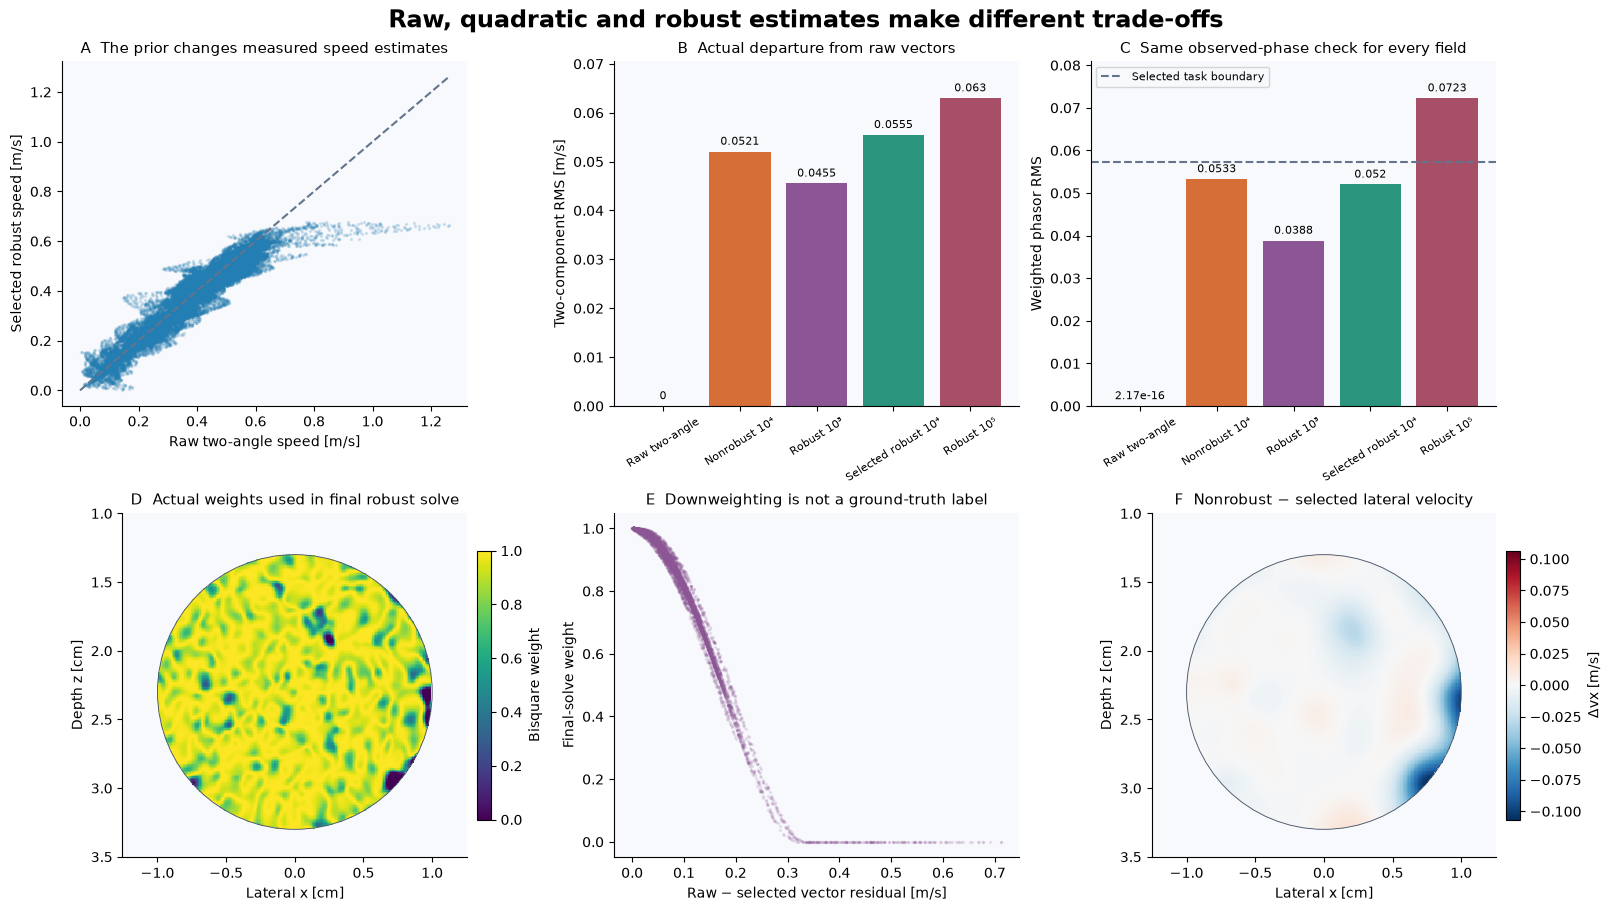

In [6]:
def fresh_packet_variant(window=11,lag=1,smoothing=1e4,robust=True):
    start=time.perf_counter();radial=[];correlations=[];variances=[]
    for beam in result['beam_iq']:
        velocity,variance,correlation=doppler_velocity(beam,window=window,lag=lag)
        radial.append(velocity);variances.append(variance);correlations.append(correlation)
    raw=invert_receive_projections(*radial)
    full,diagnostics=robust_smooth(raw,result['roi'],smoothing=smoothing,robust=robust)
    field=full.copy();field[:,~result['roi']]=0
    return {'velocity':field,'raw_velocity':raw,'smoothed_full':full,'smoothing':diagnostics,'radial':np.stack(radial),'autocorrelation':np.stack(correlations),'runtime_seconds':time.perf_counter()-start,'window':window,'lag':lag}
raw_field=result['raw_velocity'].copy();raw_field[:,~result['roi']]=0
comparisons={'Raw two-angle':{'velocity':raw_field},'Nonrobust 10⁴':fresh_packet_variant(robust=False),'Robust 10³':fresh_packet_variant(smoothing=1e3),'Selected robust 10⁴':result,'Robust 10⁵':fresh_packet_variant(smoothing=1e5)}
fig,numeric=viz.plot_comparisons(result,comparisons)
viz.export_figure(fig,'figure05_method_and_prior_comparisons',FIGURES,numeric);plt.show()

Figure5 preserves raw-versus-regularized comparison and actively evaluates additional quadratic/robust scales on the same RF. Each bar is measured, including the genuinely zero raw-from-raw vector discrepancy. Some alternatives do not meet the **selected estimate's** evaluation boundary; no threshold is retuned to admit them. Weights plotted are those used in the final solve, determined by the previous robust pass; the returned weights recomputed after the final pass are separately recorded and do not trigger an invented fourth solve. Downweighting is not a truth label for a pixel.

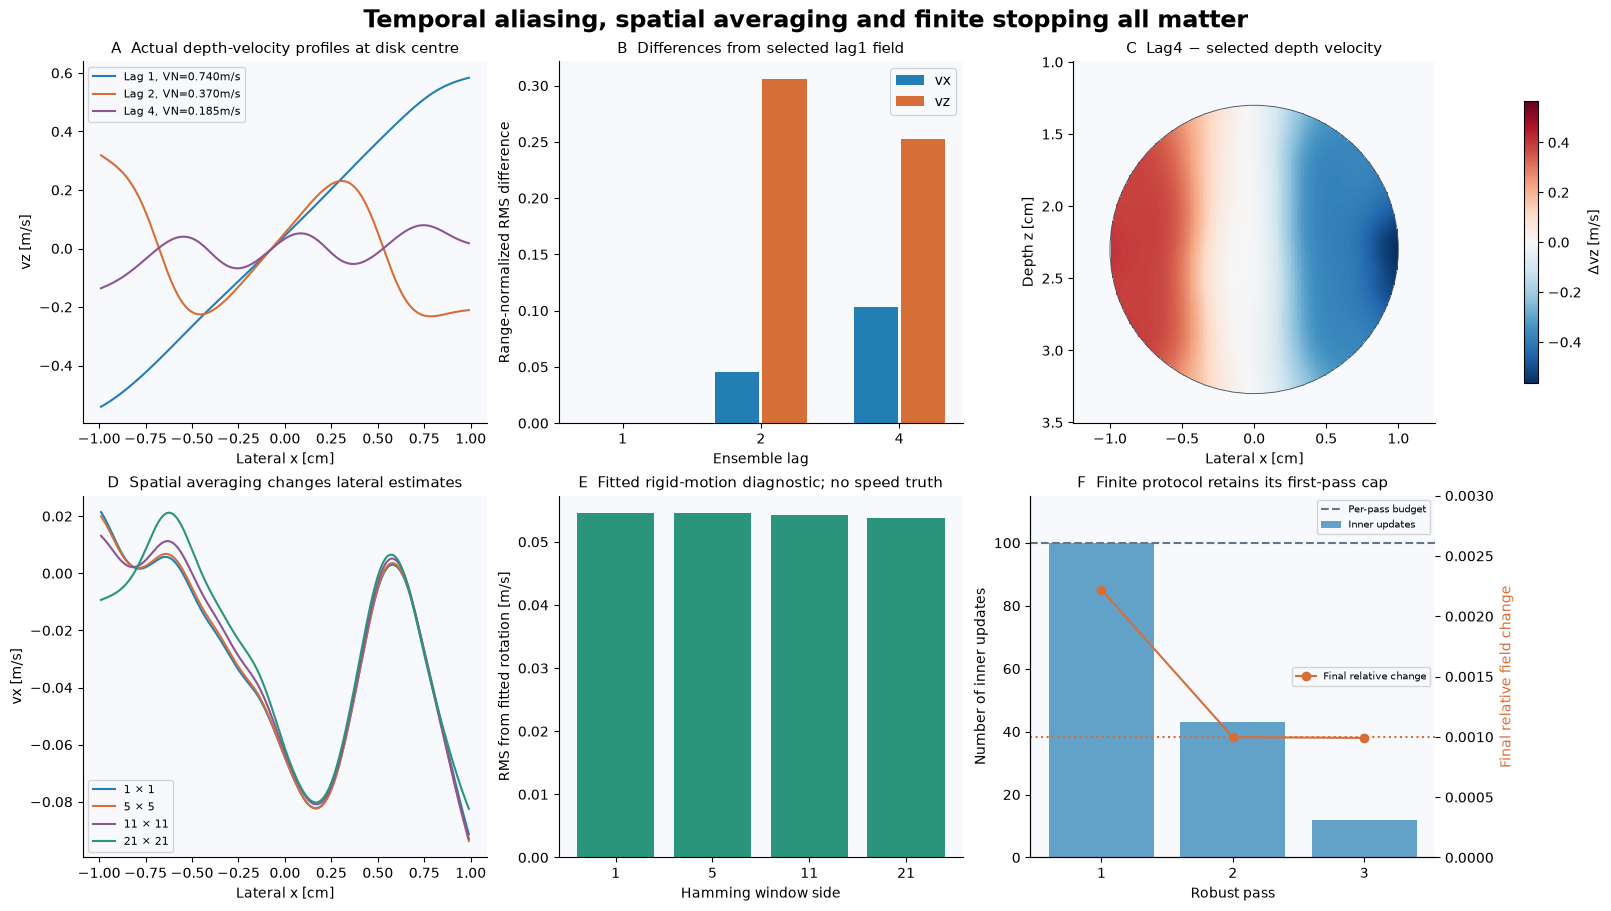

{
  "environment": {
    "sys_executable": "D:\\yan1\\agent\\AutoSkill\\imaging-101-maintainer\\research-runtime\\Scripts\\python.exe",
    "python": "3.11.11",
    "numpy": "2.4.6",
    "scipy": "1.17.1",
    "matplotlib": "3.11.1",
    "backend": "module://matplotlib_inline.backend_inline",
    "threads": {
      "OMP_NUM_THREADS": "1",
      "OPENBLAS_NUM_THREADS": "1",
      "MKL_NUM_THREADS": "1",
      "NUMEXPR_NUM_THREADS": "1"
    }
  },
  "raw_sha256": "67e1e754a8e93e7f02ba35c3fa55f869b2a48c520d228e1d96d3e3d5b584ae38",
  "full_reconstruction_seconds": 3.2178455000102986,
  "judge": {
    "status": "pass",
    "passed": true,
    "metrics": {
      "vx_ncc": 1.0,
      "vx_nrmse": 4.9102137563055166e-15,
      "vz_ncc": 1.0,
      "vz_nrmse": 1.034358962900707e-15,
      "weighted_phasor_rms": 0.05201278063077122,
      "outside_support_maxabs": 0.0
    },
    "thresholds": {
      "vx_ncc": {
        "comparison": ">=",
        "boundary": 0.9999999999999956
      },
      "vx

In [7]:
lags={1:result,2:fresh_packet_variant(lag=2),4:fresh_packet_variant(lag=4)}
windows={1:fresh_packet_variant(window=1),5:fresh_packet_variant(window=5),11:result,21:fresh_packet_variant(window=21)}
fig,numeric=viz.plot_sensitivity(result,lags,windows)
viz.export_figure(fig,'figure06_acquisition_and_stopping_sensitivity',FIGURES,numeric);plt.show()
metrics={'environment':environment,'raw_sha256':raw_hash,'full_reconstruction_seconds':reconstruction_seconds,'judge':report,'selected_history':result['smoothing']['history'],'reference_role':'Independent conditional author-method output, not measured true velocity','comparison_measurements':{},'lag_histories':{},'window_histories':{}}
for name,item in comparisons.items():
    metrics['comparison_measurements'][name]={'weighted_phasor_rms':phase_consistency(item['velocity'],result['autocorrelation'],result['roi']),'rms_from_raw_vector_mps':float(np.sqrt(np.mean((item['velocity'][:,result['roi']]-result['raw_velocity'][:,result['roi']])**2)))}
for name,items in [('lag_histories',lags),('window_histories',windows)]:
    for key,item in items.items():metrics[name][str(key)]=item['smoothing']['history']
references=ROOT/'notebooks/reference_outputs'
(references/'fresh_run.json').write_text(json.dumps(metrics,indent=2),encoding='utf8')
np.savez_compressed(references/'fresh_results.npz',reconstruction=result['velocity'][None],radial=result['radial'],autocorrelation=result['autocorrelation'],raw_vector=result['raw_velocity'],weights_used=result['smoothing']['weights_used'],weights_after_final_step=result['smoothing']['weights_after_final_step'])
if FIGURES:
    (Path(FIGURES)/'experiment_metrics.json').write_text(json.dumps(metrics,indent=2),encoding='utf8')
print(json.dumps(metrics,indent=2))

## 6. Conclusion: what is and is not established

Both complete physical velocity components are reconstructed from the actual RF observations, with explicit local travel-time, phase and robust-update mathematics. Original/cleaned agreement is independently tested at demodulation, receive operator, phase/variance, first update and complete field stages. A standalone evaluator independently explains the observed complex phase. This is stronger evidence than self-comparing a saved image.

The real field is still a conditional mechanical estimate. Neither this file nor the method reference supplies independently measured speed. The finite smoothing protocol, unknown echo statistics and phase wraps limit physical interpretation. Longer lag lowers the unambiguous directional interval, and the actually recomputed Figure6 exposes the resulting field changes. Its fitted rigid-motion residual is a diagnostic of the recovered full field; the fitted angular rate is never used as calibration, output truth or hidden input. No unobserved high-rate acquisition or Nyquist benchmark is fabricated.

The selected first smoothing pass reaches its100-update budget, followed by two shorter passes. Reporting all per-pass histories avoids confusing the source's final-pass flag with full optimization convergence. The software license is LGPL3-or-later for the official MATLAB route; the failed Python port has a separately identified license/version. The author provides real RF as example data without a separately stated redistribution license, a disclosed limitation for local research use.

Primary sources: Madiena et al., IEEE TUFFC2018, doi:10.1109/TUFFC.2018.2817885; Garcia, CSDA2010, doi:10.1016/j.csda.2009.09.020 and its2012 corrigendum doi:10.1016/j.csda.2011.12.001; Garcia, Experiments in Fluids2011, doi:10.1007/s00348-010-0985-y. Exact paper versions/hashes, original source ZIP, adapter verification, all native commands and pre-extraction freeze are indexed in the maintainer validation evidence.